# 01 · EDA: Policies
**BEV vs. ICE Motor Property Insurance**

**Purpose:** understand the policy portfolio (the exposure base) and identify **confounders**: rating factors whose distribution differs by powertrain and which must therefore be controlled for in the GLM stage.

**Input:** `data/raw/policies_raw.csv`. This notebook works on the raw extract. The light harmonisation in §1.4 is for EDA only; the definitive cleaning belongs in `src/01_etl_merge_and_clean.R`.

**Questions**
1. What is the BEV / Hybrid / ICE mix by policy count and by earned exposure?
2. Do BEVs differ systematically in vehicle value or vehicle age?
3. Do BEV drivers differ in age, licence tenure, gender or district?
4. Does the current premium already differ by powertrain?

## 1. Setup & Data Ingestion

In [1]:
# suppressWarnings hides "package built under R 4.5.x" notices
suppressWarnings(suppressPackageStartupMessages({
  library(tidyverse)
  library(scales)
  library(lubridate)
}))

options(repr.plot.width = 10, repr.plot.height = 5, repr.plot.res = 110,
        dplyr.summarise.inform = FALSE)
theme_set(theme_minimal(base_size = 12))

pt_colours <- c(BEV = "#1b9e77", Hybrid = "#7570b3", ICE = "#d95f02")

# Works whether the notebook runs from notebooks/ or from the repository root
raw_path <- c("../data/raw/policies_raw.csv", "data/raw/policies_raw.csv") |>
  keep(file.exists) |>
  first()
stopifnot(!is.na(raw_path))

# Summary statistics of a numeric variable by powertrain
summarise_by_powertrain <- function(data, var) {
  data |>
    filter(!is.na({{ var }})) |>
    group_by(Powertrain) |>
    summarise(n      = n(),
              mean   = mean({{ var }}),
              median = median({{ var }}),
              p25    = quantile({{ var }}, 0.25),
              p75    = quantile({{ var }}, 0.75))
}

# Column-percentage cross-tab: share of each powertrain's policies per level of `var`
share_table <- function(data, var) {
  data |>
    count(Powertrain, {{ var }}) |>
    group_by(Powertrain) |>
    mutate(share = percent(n / sum(n), accuracy = 0.1)) |>
    ungroup() |>
    select(-n) |>
    pivot_wider(names_from = Powertrain, values_from = share, values_fill = "0.0%")
}

### 1.1 Load and inspect structure
Dates and `Premium` are read as text on purpose: both contain mixed formats (see §1.3).

In [2]:
policies_raw <- read_csv(
  raw_path,
  col_types = cols(.default       = col_character(),
                   Driver_Age     = col_double(),
                   License_Tenure = col_double(),
                   Vehicle_Age    = col_double(),
                   Vehicle_Value  = col_double())
)

cat("Rows:", nrow(policies_raw), "| Columns:", ncol(policies_raw), "\n\n")
glimpse(policies_raw)

Rows: 38592 | Columns: 12 



Rows: 38,592
Columns: 12
$ Policy_ID      <chr> "P2198414", "P2890047", "P2276633", "P2580165", "P28147…
$ Start_Date     <chr> "2024-03-13", "2024-01-19", "2024-06-17", "2024-02-23",…
$ End_Date       <chr> "2025-03-12", "2025-01-18", "2025-06-16", "2025-02-22",…
$ District       <chr> "Jerusalem", "Haifa", "South", "Tel Aviv", "North", "Ce…
$ Driver_Age     <dbl> 22, 55, 58, 22, 17, 44, 51, 61, 39, 70, 36, 25, 62, 70,…
$ License_Tenure <dbl> 0, 35, 41, 4, 0, 27, 33, 39, 16, 47, 19, 4, 44, 52, 50,…
$ Gender         <chr> "Male", "Female", "Male", "Male", "Female", "Male", "Ma…
$ Powertrain     <chr> "ICE", "BEV", "ICE", "BEV", "ICE", "Hybrid", "ICE", "IC…
$ Fuel_Detail    <chr> "Petrol", "BEV", "Petrol", "BEV", "Petrol", "HEV", "Pet…
$ Vehicle_Age    <dbl> 14, 0, 9, 6, 11, 6, 4, 2, 7, 19, 10, 2, 8, 10, 2, 7, 8,…
$ Vehicle_Value  <dbl> 24900, 223900, 29000, 31100, 38400, 112100, 107300, 182…
$ Premium        <chr> "6995", "5582", "2560", "6635", "8191", "4660", "2890",…


In [3]:
summary(select(policies_raw, where(is.numeric)))

   Driver_Age     License_Tenure   Vehicle_Age     Vehicle_Value   
 Min.   : 17.00   Min.   : 0.00   Min.   :-1.000   Min.   :     0  
 1st Qu.: 36.00   1st Qu.:16.00   1st Qu.: 3.000   1st Qu.: 44200  
 Median : 46.00   Median :27.00   Median : 5.000   Median : 71600  
 Mean   : 47.15   Mean   :26.22   Mean   : 6.371   Mean   : 83499  
 3rd Qu.: 55.00   3rd Qu.:36.00   3rd Qu.: 9.000   3rd Qu.:109900  
 Max.   :999.00   Max.   :75.00   Max.   :28.000   Max.   :558200  
 NA's   :552      NA's   :280                      NA's   :323     

### 1.2 Missing values and `Policy_ID` integrity

In [4]:
policies_raw |>
  summarise(across(everything(), ~ sum(is.na(.x)))) |>
  pivot_longer(everything(), names_to = "column", values_to = "n_missing") |>
  mutate(pct_missing = percent(n_missing / nrow(policies_raw), accuracy = 0.01)) |>
  filter(n_missing > 0) |>
  arrange(desc(n_missing))

column,n_missing,pct_missing
<chr>,<int>,<chr>
Driver_Age,552,1.43%
Vehicle_Value,323,0.84%
License_Tenure,280,0.73%
District,180,0.47%
Gender,138,0.36%


In [5]:
conflicting_ids <- policies_raw |>
  distinct() |>
  count(Policy_ID) |>
  filter(n > 1)

tibble(
  rows                      = nrow(policies_raw),
  unique_policy_ids         = n_distinct(policies_raw$Policy_ID),
  exact_duplicate_rows      = sum(duplicated(policies_raw)),
  ids_with_conflicting_rows = nrow(conflicting_ids)
)

rows,unique_policy_ids,exact_duplicate_rows,ids_with_conflicting_rows
<int>,<int>,<int>,<int>
38592,38412,110,70


In [6]:
# Example of conflicting duplicates: only Start_Date differs
policies_raw |>
  semi_join(conflicting_ids, by = "Policy_ID") |>
  distinct() |>
  arrange(Policy_ID) |>
  select(Policy_ID, Start_Date, End_Date, Powertrain, Vehicle_Value, Premium) |>
  head(6)

Policy_ID,Start_Date,End_Date,Powertrain,Vehicle_Value,Premium
<chr>,<chr>,<chr>,<chr>,<dbl>,<chr>
P2010004,2025-01-09,2025-11-26,ICE,143500,4591
P2010004,2024-11-27,2025-11-26,ICE,143500,4591
P2033161,2024-05-21,2025-05-20,ICE,76400,5442
P2033161,2024-10-02,2025-05-20,ICE,76400,5442
P2048484,2024-06-05,2024-07-19,ICE,37700,974
P2048484,2024-03-26,2024-07-19,ICE,37700,974


### 1.3 Data-quality issues
A single audit table of every anomaly found. Each one is an action item for the ETL script.

In [7]:
p <- policies_raw
valid_fuel <- c("BEV", "HEV", "PHEV", "Petrol", "Diesel")

quality_log <- tribble(
  ~issue,                                                ~records,
  "Exact duplicate rows",                                 sum(duplicated(p)),
  "Policy_ID with conflicting rows (Start_Date differs)", nrow(conflicting_ids),
  "Start_Date in dd/mm/yyyy format",                      sum(str_detect(p$Start_Date, "^\\d{2}/\\d{2}/\\d{4}$")),
  "Start_Date placeholder 1900-01-01",                    sum(p$Start_Date == "1900-01-01"),
  "Premium stored as text (currency symbol / commas)",    sum(str_detect(p$Premium, "[^0-9.-]")),
  "Premium <= 0 (sentinel -1 / 0)",                       sum(parse_number(p$Premium) <= 0),
  "Driver_Age = 999 (sentinel)",                          sum(p$Driver_Age == 999, na.rm = TRUE),
  "License_Tenure > Driver_Age - 16 (impossible)",        sum(p$License_Tenure > p$Driver_Age - 16, na.rm = TRUE),
  "Vehicle_Age = -1",                                     sum(p$Vehicle_Age < 0, na.rm = TRUE),
  "Vehicle_Value = 0",                                    sum(p$Vehicle_Value == 0, na.rm = TRUE),
  "Vehicle_Value recorded in thousands (0 < value < 1,000)", sum(between(p$Vehicle_Value, 1e-9, 999), na.rm = TRUE),
  "Fuel_Detail non-standard label",                       sum(!p$Fuel_Detail %in% valid_fuel),
  "Powertrain = BEV but Fuel_Detail = PHEV",              sum(p$Powertrain == "BEV" & p$Fuel_Detail == "PHEV"),
  "Gender non-standard code (F, M, U, N/A, case)",        sum(!is.na(p$Gender) & !p$Gender %in% c("Male", "Female")),
  "District label variant (TLV, Tel-Aviv, tel aviv)",     sum(p$District %in% c("TLV", "Tel-Aviv", "tel aviv"))
)
quality_log

issue,records
<chr>,<int>
Exact duplicate rows,110
Policy_ID with conflicting rows (Start_Date differs),70
Start_Date in dd/mm/yyyy format,1201
Start_Date placeholder 1900-01-01,26
Premium stored as text (currency symbol / commas),202
Premium <= 0 (sentinel -1 / 0),40
Driver_Age = 999 (sentinel),65
License_Tenure > Driver_Age - 16 (impossible),85
Vehicle_Age = -1,35


### 1.4 EDA working copy
Minimal harmonisation so the analysis below is meaningful:
- Drop exact duplicates. For conflicting IDs, keep the row with the longest valid exposure.
- Parse both date formats and compute **exposure = (End − Start + 1) / 365.25** years. Exposure ≤ 0 or > 1 year is set to `NA`.
- Set sentinels and impossible values to `NA`. Rescale vehicle values recorded in ₪ thousands (×1,000).
- Unify the `Gender`, `District` and `Fuel_Detail` labels.

In [8]:
policies <- policies_raw |>
  distinct() |>
  mutate(
    start_date     = as_date(parse_date_time(Start_Date, orders = c("Ymd", "dmY"))),
    end_date       = ymd(End_Date),
    exposure       = as.numeric(end_date - start_date + 1) / 365.25,
    exposure       = if_else(exposure > 0 & exposure <= 1.01, exposure, NA_real_),
    Premium        = if_else(parse_number(Premium) > 0, parse_number(Premium), NA_real_),
    Powertrain     = factor(str_trim(Powertrain), levels = c("BEV", "Hybrid", "ICE")),
    fuel_code      = str_to_upper(str_trim(Fuel_Detail)),
    Fuel_Detail    = case_when(fuel_code %in% c("BEV", "EV", "ELECTRIC") ~ "BEV",
                               fuel_code %in% c("DIESEL", "DIESAL")      ~ "Diesel",
                               fuel_code == "PETROL"                     ~ "Petrol",
                               .default = fuel_code),
    gender_code    = str_to_upper(str_trim(Gender)),
    Gender         = case_when(gender_code %in% c("M", "MALE")   ~ "Male",
                               gender_code %in% c("F", "FEMALE") ~ "Female"),
    District       = if_else(str_to_lower(District) %in% c("tlv", "tel-aviv", "tel aviv"),
                             "Tel Aviv", District),
    Driver_Age     = if_else(Driver_Age > 100, NA_real_, Driver_Age),
    License_Tenure = if_else(License_Tenure > Driver_Age - 16, NA_real_, License_Tenure),
    Vehicle_Age    = if_else(Vehicle_Age < 0, NA_real_, Vehicle_Age),
    Vehicle_Value  = case_when(Vehicle_Value <= 0   ~ NA_real_,
                               Vehicle_Value < 1000 ~ Vehicle_Value * 1000,
                               .default = Vehicle_Value)
  ) |>
  select(-fuel_code, -gender_code) |>
  slice_max(exposure, n = 1, with_ties = FALSE, by = Policy_ID)

cat("Policies in EDA copy:", nrow(policies),
    "| unique IDs:", n_distinct(policies$Policy_ID),
    "| without valid exposure:", sum(is.na(policies$exposure)), "\n")

Policies in EDA copy: 38412 | unique IDs: 38412 | without valid exposure: 84 


## 2. Portfolio Composition & Powertrain Mix
Earned exposure in vehicle-years is the actuarial volume measure. It is the denominator for claim frequency in notebooks 02–04.

In [9]:
mix <- policies |>
  group_by(Powertrain) |>
  summarise(policies       = n(),
            exposure_years = sum(exposure, na.rm = TRUE),
            mean_exposure  = mean(exposure, na.rm = TRUE)) |>
  mutate(policy_share   = policies / sum(policies),
         exposure_share = exposure_years / sum(exposure_years))

mix |>
  mutate(exposure_years = comma(exposure_years, accuracy = 1),
         mean_exposure  = number(mean_exposure, accuracy = 0.01),
         across(ends_with("share"), ~ percent(.x, accuracy = 0.1)))

Powertrain,policies,exposure_years,mean_exposure,policy_share,exposure_share
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
BEV,4349,"4,121",0.95,11.3%,11.3%
Hybrid,8195,"7,754",0.95,21.3%,21.3%
ICE,25868,"24,473",0.95,67.3%,67.3%


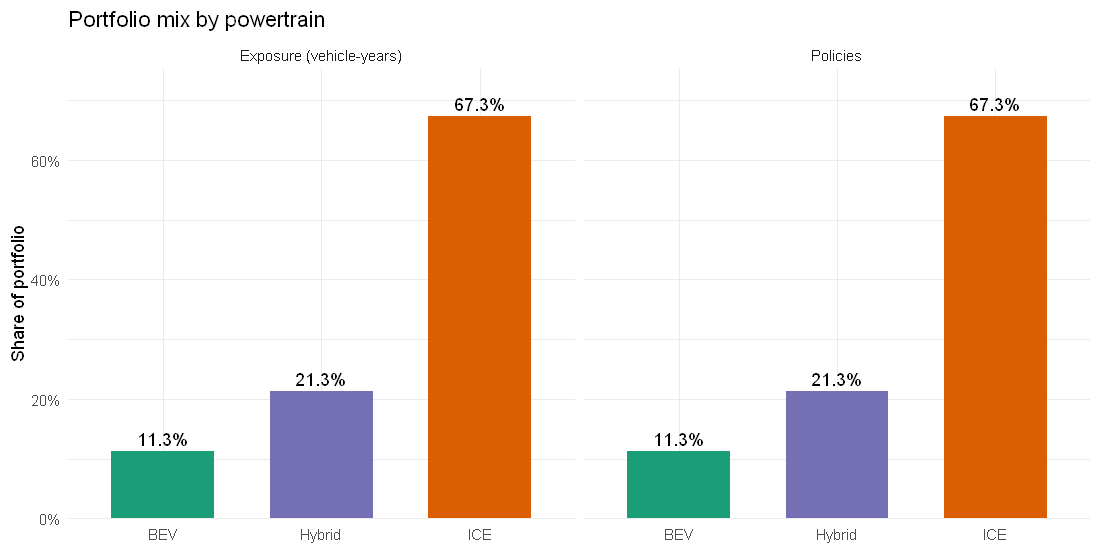

In [10]:
mix |>
  select(Powertrain, `Policies` = policy_share, `Exposure (vehicle-years)` = exposure_share) |>
  pivot_longer(-Powertrain, names_to = "measure", values_to = "share") |>
  ggplot(aes(Powertrain, share, fill = Powertrain)) +
  geom_col(width = 0.65) +
  geom_text(aes(label = percent(share, accuracy = 0.1)), vjust = -0.4) +
  facet_wrap(~ measure) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_continuous(labels = percent, expand = expansion(mult = c(0, 0.12))) +
  labs(title = "Portfolio mix by powertrain",
       x = NULL, y = "Share of portfolio")

### 2.1 Exposure duration
About 89% of policies run a full year. Partial-year policies (cancellations or mid-term starts) contribute only partial exposure, which is why the frequency GLM needs the `log(exposure)` offset.

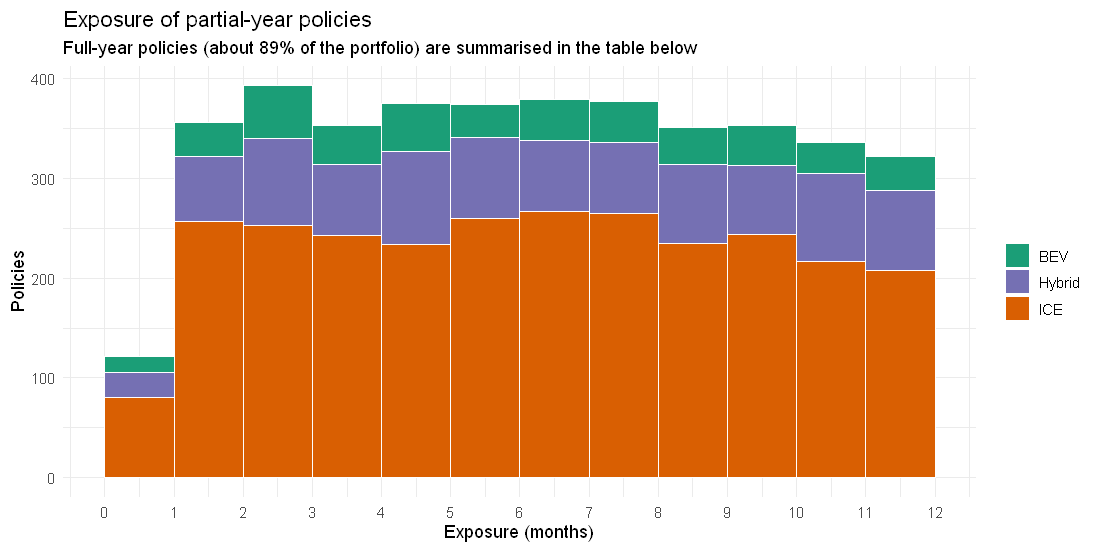

In [11]:
policies |>
  filter(exposure < 0.99) |>
  ggplot(aes(exposure * 12, fill = Powertrain)) +
  geom_histogram(binwidth = 1, boundary = 0, colour = "white") +
  scale_fill_manual(values = pt_colours) +
  scale_x_continuous(breaks = 0:12) +
  scale_y_continuous(labels = comma) +
  labs(title = "Exposure of partial-year policies",
       subtitle = "Full-year policies (about 89% of the portfolio) are summarised in the table below",
       x = "Exposure (months)", y = "Policies", fill = NULL)

In [12]:
policies |>
  filter(!is.na(exposure)) |>
  group_by(Powertrain) |>
  summarise(full_year_share = percent(mean(exposure >= 0.99), accuracy = 0.1),
            median_months   = number(median(exposure) * 12, accuracy = 0.1))

Powertrain,full_year_share,median_months
<fct>,<chr>,<chr>
BEV,89.7%,12.0
Hybrid,89.2%,12.0
ICE,89.3%,12.0


## 3. Confounder Check 1: Vehicle Characteristics
### 3.1 Vehicle value (sum insured)
*Key check: are BEVs systematically more expensive? A higher sum insured mechanically raises claim severity.*

In [13]:
summarise_by_powertrain(policies, Vehicle_Value) |>
  mutate(across(mean:p75, ~ comma(.x, accuracy = 100, prefix = "₪")))

Powertrain,n,mean,median,p25,p75
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
BEV,4345,"₪147,600","₪140,000","₪100,200","₪185,200"
Hybrid,8183,"₪102,900","₪93,800","₪64,800","₪129,500"
ICE,25519,"₪67,000","₪59,600","₪37,200","₪88,000"


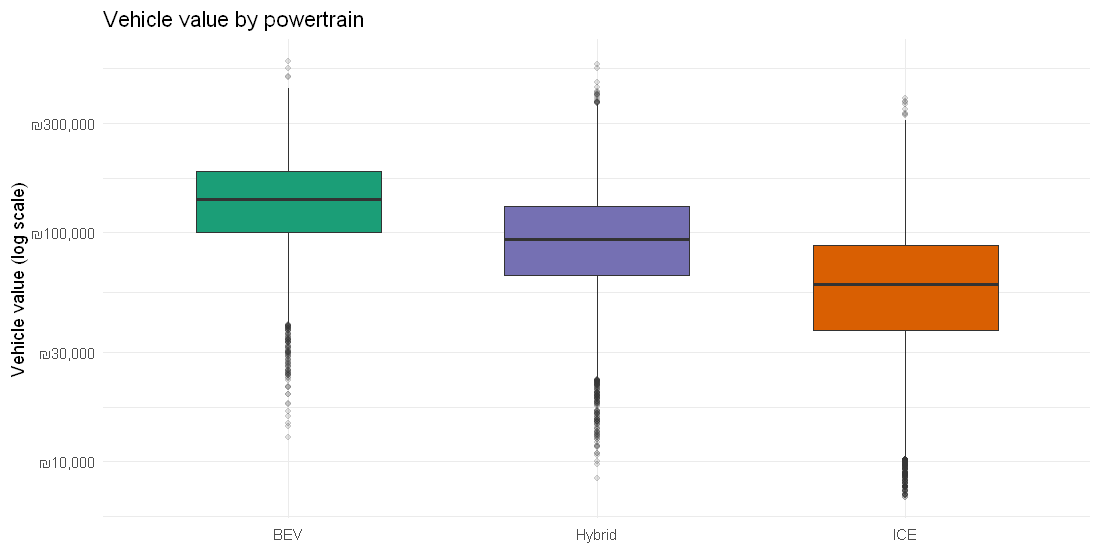

In [14]:
policies |>
  filter(!is.na(Vehicle_Value)) |>
  ggplot(aes(Powertrain, Vehicle_Value, fill = Powertrain)) +
  geom_boxplot(outlier.alpha = 0.15, width = 0.6) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_log10(labels = label_comma(prefix = "₪")) +
  labs(title = "Vehicle value by powertrain",
       x = NULL, y = "Vehicle value (log scale)")

### 3.2 Vehicle age
*Key check: are BEVs substantially newer? Newer cars have higher repair costs and different total-loss behaviour.*

In [15]:
summarise_by_powertrain(policies, Vehicle_Age) |>
  mutate(across(mean:p75, ~ number(.x, accuracy = 0.1)))

Powertrain,n,mean,median,p25,p75
<fct>,<int>,<chr>,<chr>,<chr>,<chr>
BEV,4344,2.6,2.0,1.0,3.0
Hybrid,8189,4.7,4.0,2.0,6.0
ICE,25844,7.6,6.0,4.0,10.0


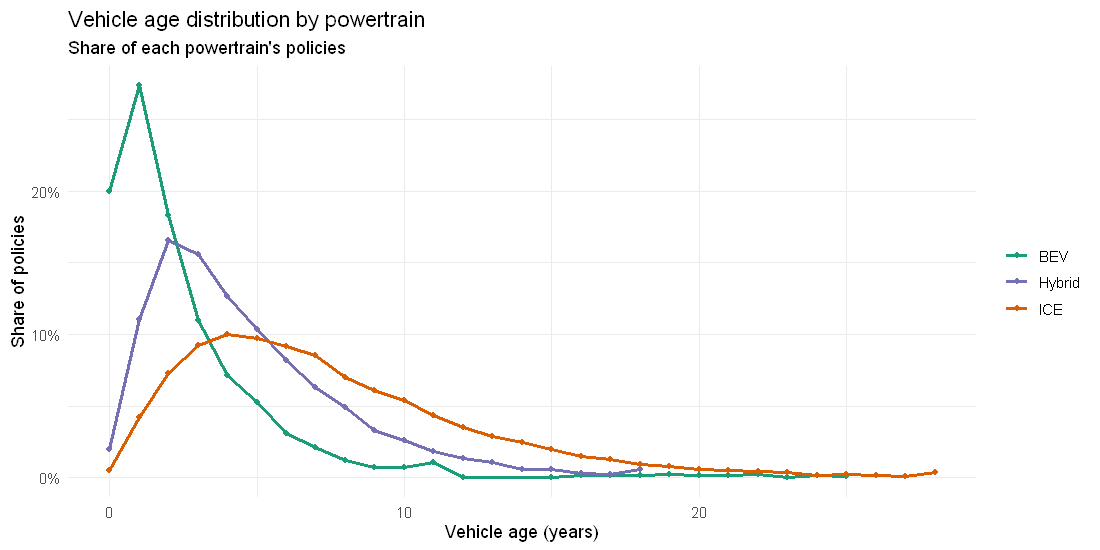

In [16]:
policies |>
  filter(!is.na(Vehicle_Age)) |>
  count(Powertrain, Vehicle_Age) |>
  group_by(Powertrain) |>
  mutate(share = n / sum(n)) |>
  ggplot(aes(Vehicle_Age, share, colour = Powertrain)) +
  geom_line(linewidth = 1) +
  geom_point(size = 1.5) +
  scale_colour_manual(values = pt_colours) +
  scale_y_continuous(labels = percent) +
  labs(title = "Vehicle age distribution by powertrain",
       subtitle = "Share of each powertrain's policies",
       x = "Vehicle age (years)", y = "Share of policies", colour = NULL)

### 3.3 Vehicle segment
The extract has **no body-type or segment field**. Two available proxies:
- **Value tiers** approximate the market segment (economy → luxury).
- **Fuel_Detail** shows the technology sub-type within each powertrain and exposes coding conflicts.

In [17]:
policies <- policies |>
  mutate(value_tier = cut(Vehicle_Value,
                          breaks = c(0, 50e3, 100e3, 150e3, 250e3, Inf),
                          labels = c("< 50k", "50–100k", "100–150k", "150–250k", "250k+"),
                          right  = FALSE))

share_table(policies, value_tier)

value_tier,BEV,Hybrid,ICE
<fct>,<chr>,<chr>,<chr>
< 50k,4.3%,13.9%,38.8%
50–100k,20.3%,41.0%,41.8%
100–150k,31.2%,28.8%,14.1%
150–250k,36.4%,14.1%,3.8%
250k+,7.6%,2.0%,0.2%
NA,0.1%,0.1%,1.3%


In [18]:
policies |>
  count(Fuel_Detail, Powertrain) |>
  pivot_wider(names_from = Powertrain, values_from = n, values_fill = 0)

Fuel_Detail,BEV,ICE,Hybrid
<chr>,<int>,<int>,<int>
BEV,4274,0,0
Diesel,0,3603,0
HEV,0,0,6924
PHEV,75,0,1271
Petrol,0,22265,0


## 4. Confounder Check 2: Driver Demographics
### 4.1 Driver age & licence tenure
*Key check: is the EV-adopter demographic skewed (e.g. older and more experienced, or younger)?*

In [19]:
bind_rows(
  `Driver age`     = summarise_by_powertrain(policies, Driver_Age),
  `Licence tenure` = summarise_by_powertrain(policies, License_Tenure),
  .id = "variable"
) |>
  mutate(across(mean:p75, ~ number(.x, accuracy = 0.1)))

variable,Powertrain,n,mean,median,p25,p75
<chr>,<fct>,<int>,<chr>,<chr>,<chr>,<chr>
Driver age,BEV,4284,45.3,46.0,35.0,56.0
Driver age,Hybrid,8072,45.4,46.0,36.0,55.0
Driver age,ICE,25442,45.6,46.0,36.0,55.0
Licence tenure,BEV,4240,26.0,26.0,16.0,36.0
Licence tenure,Hybrid,7991,26.1,26.0,16.0,36.0
Licence tenure,ICE,25206,26.3,27.0,16.0,36.0


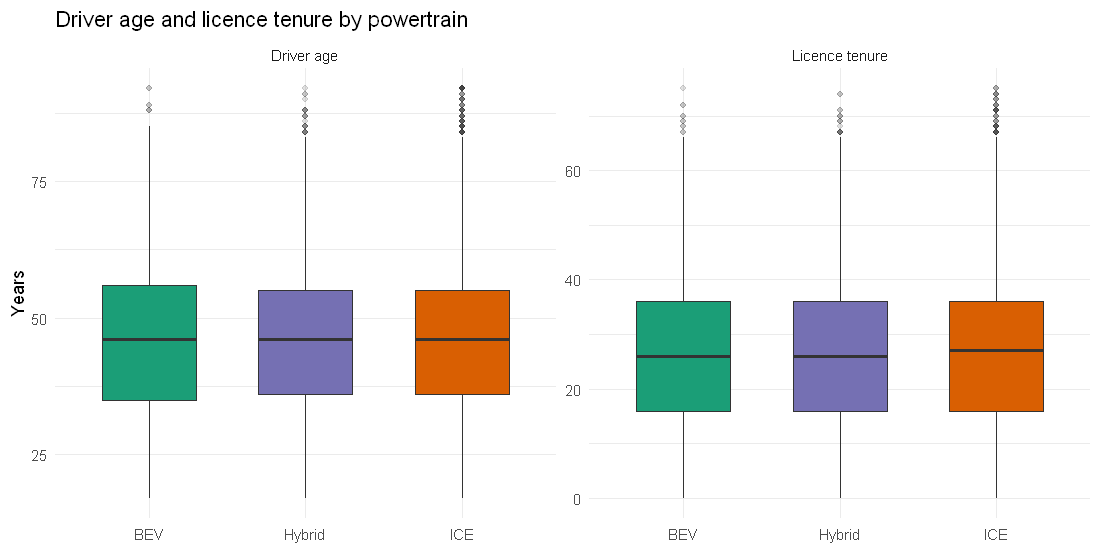

In [20]:
policies |>
  select(Powertrain, `Driver age` = Driver_Age, `Licence tenure` = License_Tenure) |>
  pivot_longer(-Powertrain, names_to = "variable", values_to = "years") |>
  filter(!is.na(years)) |>
  ggplot(aes(Powertrain, years, fill = Powertrain)) +
  geom_boxplot(outlier.alpha = 0.15, width = 0.6) +
  facet_wrap(~ variable, scales = "free_y") +
  scale_fill_manual(values = pt_colours, guide = "none") +
  labs(title = "Driver age and licence tenure by powertrain",
       x = NULL, y = "Years")

### 4.2 Gender & district (share of each powertrain's policies)

In [21]:
share_table(policies, Gender)

Gender,BEV,Hybrid,ICE
<chr>,<chr>,<chr>,<chr>
Female,46.8%,45.9%,46.5%
Male,52.1%,53.0%,52.4%
NA,1.1%,1.0%,1.1%


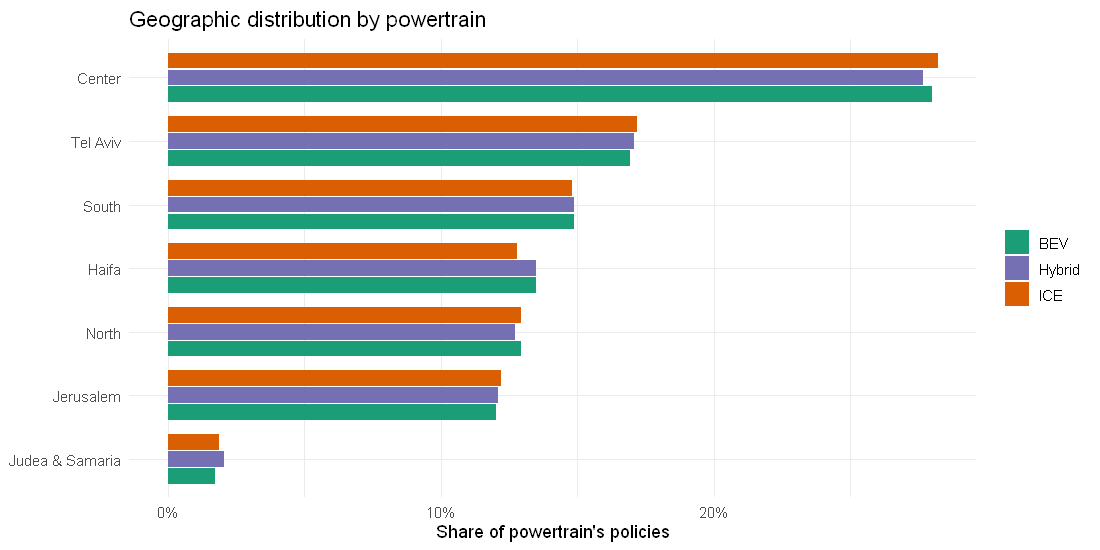

In [22]:
policies |>
  filter(!is.na(District)) |>
  count(Powertrain, District) |>
  group_by(Powertrain) |>
  mutate(share = n / sum(n)) |>
  ungroup() |>
  mutate(District = fct_reorder(District, share, .fun = sum)) |>
  ggplot(aes(share, District, fill = Powertrain)) +
  geom_col(position = position_dodge(width = 0.8), width = 0.75) +
  scale_fill_manual(values = pt_colours) +
  scale_x_continuous(labels = percent) +
  labs(title = "Geographic distribution by powertrain",
       x = "Share of powertrain's policies", y = NULL, fill = NULL)

## 5. Policy Coverage & Pricing Factors
The extract contains **no deductible, voluntary-excess or coverage-type fields**. We assume all policies are the same property-damage product.

The only pricing variable available is the **current premium**. Premium as a share of vehicle value (the *premium rate*) shows whether the existing tariff already charges BEVs differently once the higher sum insured is taken into account.

In [23]:
policies <- policies |>
  mutate(premium_rate = Premium / Vehicle_Value)

bind_rows(
  `Premium (₪)`            = summarise_by_powertrain(policies, Premium) |>
                               mutate(across(mean:p75, ~ comma(.x, accuracy = 1))),
  `Premium rate (% value)` = summarise_by_powertrain(policies, premium_rate) |>
                               mutate(across(mean:p75, ~ percent(.x, accuracy = 0.01))),
  .id = "measure"
)

measure,Powertrain,n,mean,median,p25,p75
<chr>,<fct>,<int>,<chr>,<chr>,<chr>,<chr>
Premium (₪),BEV,4343,"5,113","4,797","3,921","5,782"
Premium (₪),Hybrid,8182,"4,778","4,423","3,555","5,448"
Premium (₪),ICE,25847,"3,779","3,506","2,689","4,438"
Premium rate (% value),BEV,4339,4.37%,3.34%,2.69%,4.30%
Premium rate (% value),Hybrid,8170,5.93%,4.57%,3.61%,6.01%
Premium rate (% value),ICE,25499,7.62%,5.75%,4.38%,8.10%


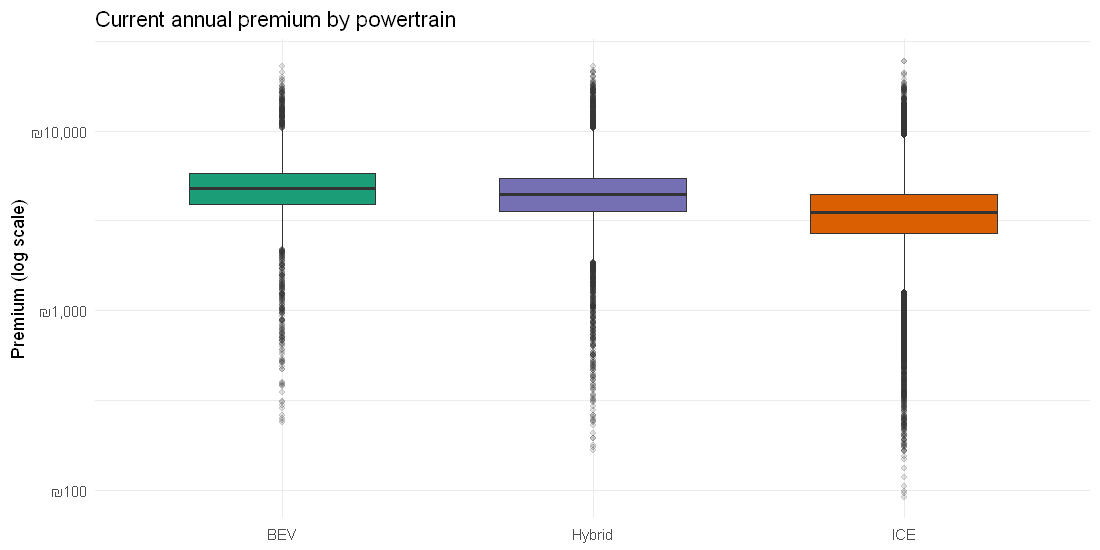

In [24]:
policies |>
  filter(!is.na(Premium)) |>
  ggplot(aes(Powertrain, Premium, fill = Powertrain)) +
  geom_boxplot(outlier.alpha = 0.15, width = 0.6) +
  scale_fill_manual(values = pt_colours, guide = "none") +
  scale_y_log10(labels = label_comma(prefix = "₪")) +
  labs(title = "Current annual premium by powertrain",
       x = NULL, y = "Premium (log scale)")

## 6. Key Findings & Implications for Modelling

**1. Portfolio mix.** After de-duplication there are 38,412 policies and about 36,350 vehicle-years of exposure. BEVs make up **11.3%** (≈ 4,100 vehicle-years), Hybrids 21.3% and ICE 67.3%. Policy share and exposure share are identical, and about 89% of policies run a full year in every group. Exposure duration is therefore *not* a confounder, but the frequency GLM still needs the `log(exposure)` offset for the partial-year ~11%.

**2. Vehicle value is the main confounder.** The median BEV is worth **₪140k vs. ₪60k for ICE (≈ 2.3×)**. 44% of BEVs are above ₪150k, compared with 4% of ICE vehicles. Any raw BEV–ICE gap in claim severity or total-loss rate will be confounded with sum insured. → Include `Vehicle_Value` (log-scale or tiers) in the severity and pure-premium GLMs. Also consider modelling severity relative to value (damage ratio).

**3. BEVs are much newer.** The median vehicle age is **2 years for BEV vs. 6 for ICE** (Hybrid 4), and BEVs older than about 8 years are almost absent. → Include vehicle-age bands in all models. Because value and age are correlated with each other and with powertrain, check for multicollinearity (VIF), and keep the bands coarse where BEV cells are sparse.

**4. Driver demographics are balanced.** Driver age (median 46), licence tenure (median 26–27), gender split (≈ 47% / 53%) and district mix are almost identical across powertrains, differing by about 1 percentage point at most. This portfolio shows no EV-adopter demographic skew; these factors are ordinary rating variables, not confounders.

**5. The current tariff already loads BEVs, but less than in proportion to value.** The median BEV premium is ₪4.8k vs. ₪3.5k for ICE (+37%). As a share of vehicle value, however, BEVs pay **3.3% vs. 5.8%**. Whether that rate is adequate is the central question for notebooks 02–04.

**Modelling decisions carried forward**
- Keep **Hybrid as a separate Powertrain level** (do not pool it with ICE), and use **ICE as the reference level**.
- Coverage, deductible and vehicle-segment fields are **not in the extract**. Confirm with the data provider that all policies share the same property-damage cover.

**ETL action items for `src/01_etl_merge_and_clean.R`** (see the audit table in §1.3)
- Remove the 110 exact duplicate rows. Resolve the 70 `Policy_ID`s whose rows differ only in `Start_Date` (here we kept the longest valid exposure).
- Parse the mixed date formats (1,201 `dd/mm/yyyy`) and treat the `1900-01-01` placeholder as missing. Drop records whose exposure is not in (0, 1] years.
- Parse `Premium` text (₪ and thousands separators) and set `-1` / `0` premiums to missing.
- Treat `Driver_Age = 999`, `Vehicle_Age = -1` and `Vehicle_Value = 0` as missing. Rescale the 130 vehicle values recorded in ₪ thousands.
- Harmonise the `Gender`, `District` and `Fuel_Detail` labels. Resolve the 75 policies with `Powertrain = BEV` but `Fuel_Detail = PHEV`, which most likely belong under Hybrid.